# Nudge vs Base — Physical Accuracy Comparison

Compares physical occlusion accuracy with and without the reflective-surface nudge across three experiment types: base, thinking, and tool use.

In [1]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [2]:
import json
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({'font.family': 'Arial', 'font.size': 38})

ANNOTATIONS_PATH = 'data/combined_output/annotations.json'
JUDGE_MODELS = ['gpt-5.4', 'claude-opus-4-6']

with open(ANNOTATIONS_PATH) as f:
    annotations = json.load(f)
physical_map = {str(item['id']): item['physical'] for item in annotations}

DISPLAY = {
    'gpt-5.4':                                                    'GPT-5.4',
    'claude-opus-4-6':                                            'Claude\nOpus 4.6',
    'gemini-3.1-pro-preview':                                     'Gemini\n3.1 Pro',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c':           'Llama 4\nMaverick',
    'Qwen3-VL-8B-Instruct':                                       'Qwen 3\nVL 8B',
}

def load_judged(directory, stem):
    path = os.path.join(directory, f'{stem}_judged_results.json')
    if not os.path.exists(path):
        return []
    with open(path) as f:
        return json.load(f)

def accuracy_by_physicality(judged_data, is_physical, judge_models=JUDGE_MODELS):
    total, correct = 0, 0.0
    for item in judged_data:
        if physical_map.get(str(item['id'])) != is_physical:
            continue
        vd = item.get('occluded_correct', {})
        scores = [vd[jm] for jm in judge_models if jm in vd and vd[jm] is not None]
        if not scores:
            continue
        correct += any(scores)
        total += 1
    return correct / total * 100 if total else None

def physical_accuracy(judged_data, judge_models=JUDGE_MODELS):
    return accuracy_by_physicality(judged_data, True, judge_models)

def nonphysical_accuracy(judged_data, judge_models=JUDGE_MODELS):
    return accuracy_by_physicality(judged_data, False, judge_models)

print('Loaded', sum(physical_map.values()), 'physical entries')

Loaded 197 physical entries


In [3]:
# --- Experiment configs ---
EXPERIMENTS = [
    {
        'title': 'Base',
        'stems': ['gpt-5.4', 'claude-opus-4-6', 'gemini-3.1-pro-preview',
                  'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c',
                  'Qwen3-VL-8B-Instruct'],
        'base_dir':              'data/eval_results',
        'nudge_dir':             'data/eval_results_nudge',
        'occlusion_dir':         None,
        'show_nonphys':          True,
        'occlusion_only_stems':  [],
    },
    {
        'title': 'Thinking',
        'stems': ['gpt-5.4', 'claude-opus-4-6'],
        'base_dir':              'data/eval_results_thinking',
        'nudge_dir':             'data/eval_results_thinking_nudge',
        'occlusion_dir':         'data/eval_results_thinking_occlusion_nudge',
        'show_nonphys':          True,
    },
    {
        'title': 'Tool Use',
        'stems': ['gpt-5.4', 'claude-opus-4-6'],
        'base_dir':              'data/eval_results_tool_use_thinking_v2',
        'nudge_dir':             'data/eval_results_tool_use_thinking_nudge',
        'occlusion_dir':         'data/eval_results_tool_use_thinking_occlusion_nudge',
        'show_nonphys':          False,  # filled from Thinking below
    },
]

# Known values not yet in judged results files. Qwen's was scored as the mean of the
# two judges, not either-judge; rescore it once its judged results file exists.
HARDCODED_NUDGE = {
    ('Base', 'Qwen3-VL-8B-Instruct', 'nudge'): 25.7,
}

results = {}
for exp in EXPERIMENTS:
    rows = []
    for stem in exp['stems']:
        base_data  = load_judged(exp['base_dir'],  stem)
        nudge_data = load_judged(exp['nudge_dir'], stem)
        occ_data   = load_judged(exp['occlusion_dir'], stem) if exp['occlusion_dir'] else None

        nudge_val = (HARDCODED_NUDGE.get((exp['title'], stem, 'nudge'))
                     or physical_accuracy(nudge_data))

        row = {
            'model':     DISPLAY[stem],
            'base':      physical_accuracy(base_data),
            'nudge':     nudge_val,
            'occlusion': physical_accuracy(occ_data) if occ_data is not None else None,
            'nonphys':   nonphysical_accuracy(base_data) if exp['show_nonphys'] else None,
        }
        rows.append(row)
        line = (f"[{exp['title']}] {DISPLAY[stem]:25s}"
                f"  base={row['base']:.1f}%" if row['base'] else f"[{exp['title']}] {DISPLAY[stem]:25s}  base=N/A")
        if row['nudge'] is not None:
            line += f"  steer(short)={row['nudge']:.1f}%  delta={row['nudge']-row['base']:+.1f}pp"
        if row['occlusion'] is not None:
            line += f"  steer(long)={row['occlusion']:.1f}%  delta={row['occlusion']-row['base']:+.1f}pp"
        if row['nonphys'] is not None:
            line += f"  non-phys={row['nonphys']:.1f}%"
        print(line)

    for stem in exp.get('occlusion_only_stems', []):
        occ_data = load_judged(exp['occlusion_dir'], stem) if exp['occlusion_dir'] else None
        row = {
            'model':     DISPLAY[stem],
            'base':      None,
            'nudge':     None,
            'occlusion': physical_accuracy(occ_data) if occ_data else None,
            'nonphys':   None,
        }
        rows.append(row)
        line = f"[{exp['title']}] {DISPLAY[stem]:25s}  base=N/A  steer(short)=N/A"
        if row['occlusion'] is not None:
            line += f"  steer(long)={row['occlusion']:.1f}%  delta=N/A"
        print(line)

    results[exp['title']] = rows
    print()
# Tool Use has no non-physical items — borrow inferential from Thinking
thinking_nonphys = {r["model"]: r["nonphys"] for r in results["Thinking"]}
for row in results["Tool Use"]:
    row["nonphys"] = thinking_nonphys.get(row["model"])
    if row["nonphys"] is not None:
        print(f"[Tool Use] {row['model']:<25}  inferential (from Thinking) = {row['nonphys']:.1f}%")

[Base] GPT-5.4                    base=37.6%  steer(short)=42.1%  delta=+4.6pp  non-phys=62.4%
[Base] Claude
Opus 4.6            base=51.8%  steer(short)=58.4%  delta=+6.6pp  non-phys=75.1%
[Base] Gemini
3.1 Pro             base=71.6%  steer(short)=75.6%  delta=+4.1pp  non-phys=87.8%
[Base] Llama 4
Maverick           base=31.6%  steer(short)=37.1%  delta=+5.4pp  non-phys=42.0%
[Base] Qwen 3
VL 8B               base=20.9%  steer(short)=25.7%  delta=+4.8pp  non-phys=46.4%

[Thinking] GPT-5.4                    base=51.8%  steer(short)=69.2%  delta=+17.4pp  steer(long)=57.6%  delta=+5.9pp  non-phys=82.0%
[Thinking] Claude
Opus 4.6            base=44.7%  steer(short)=49.7%  delta=+5.1pp  steer(long)=52.3%  delta=+7.6pp  non-phys=72.4%

[Tool Use] GPT-5.4                    base=46.7%  steer(short)=49.5%  delta=+2.8pp  steer(long)=44.7%  delta=-2.0pp
[Tool Use] Claude
Opus 4.6            base=51.8%  steer(short)=55.3%  delta=+3.6pp  steer(long)=59.4%  delta=+7.6pp

[Tool Use] GPT-5.4       

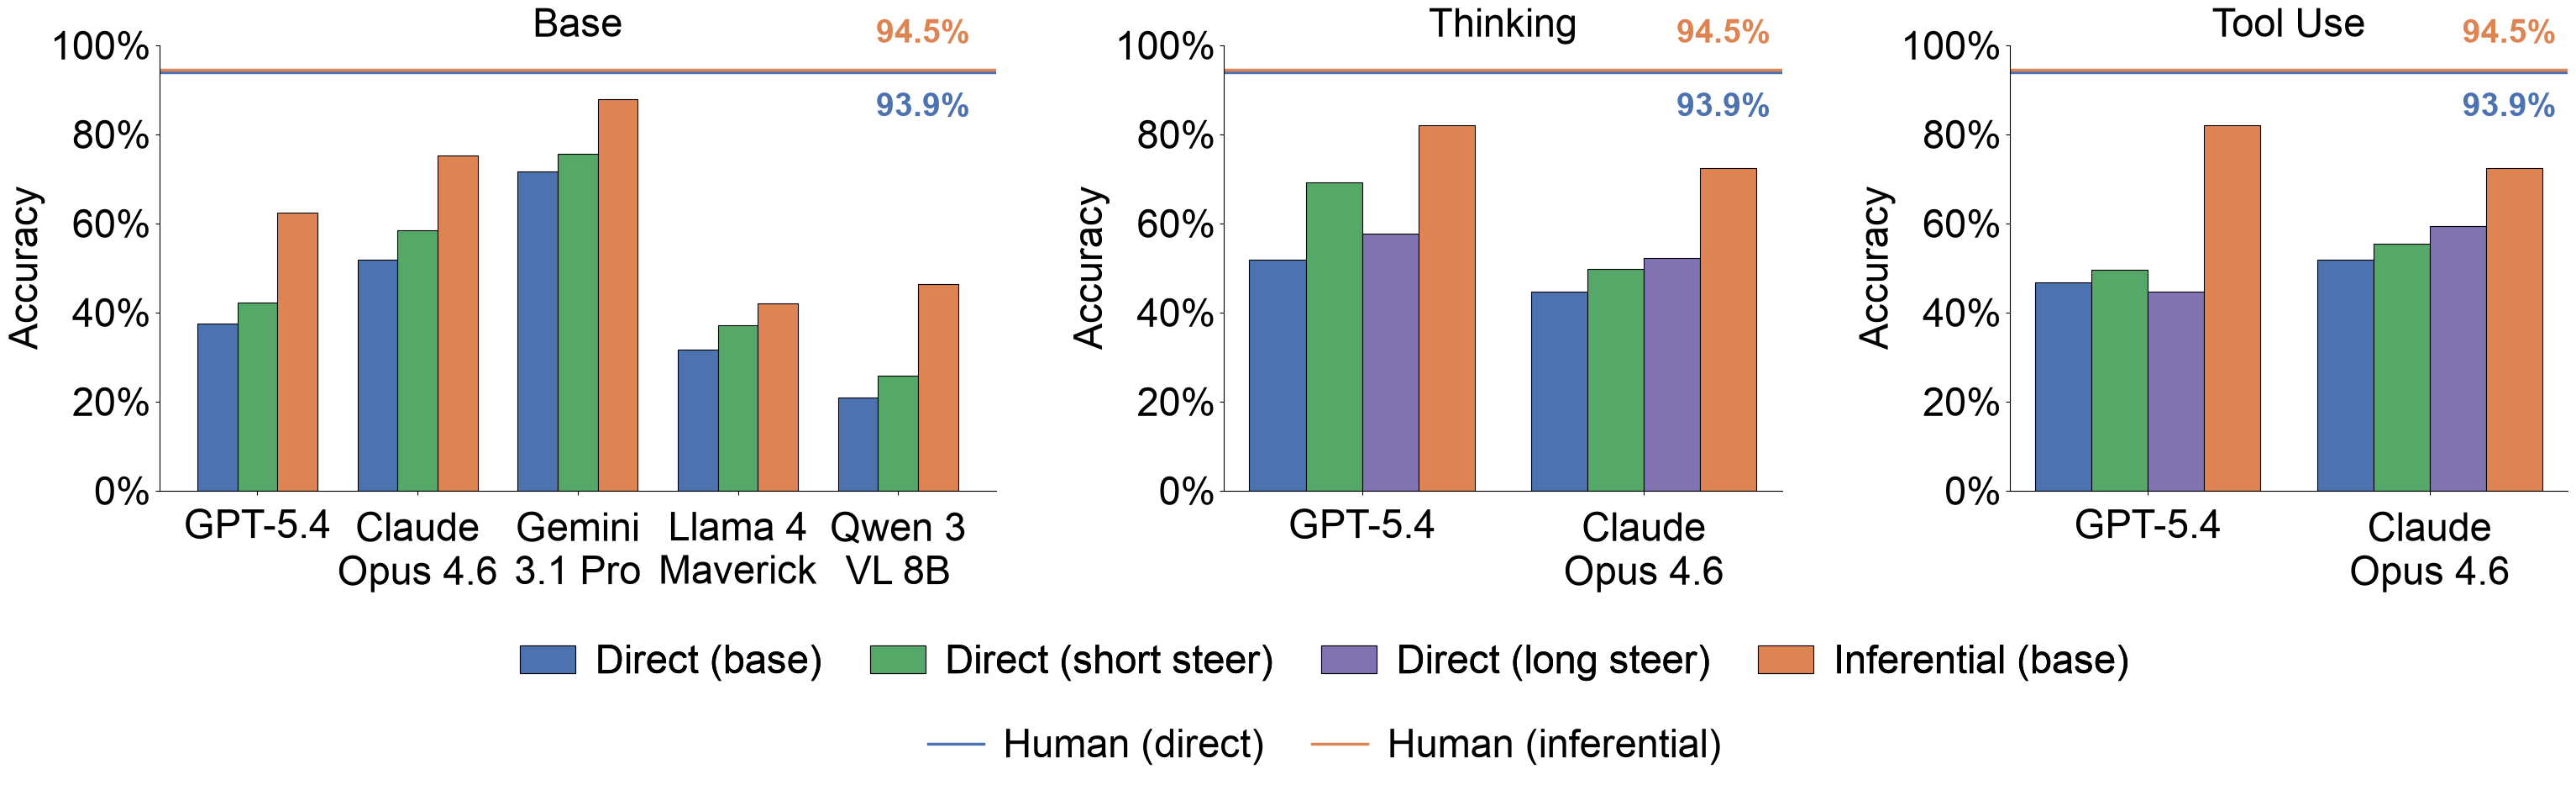

In [4]:
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

BASE_COLOR      = '#4C72B0'
NUDGE_COLOR     = '#55A868'
OCCLUSION_COLOR = '#8172B2'
NONPHYS_COLOR   = '#DD8452'

HUMAN_PHYS_SOLV = 93.9
HUMAN_INF_SOLV  = 94.5

def _nan(lst):
    return [v if v is not None else float('nan') for v in lst]

fig, axes = plt.subplots(1, 3, figsize=(37, 10),
                         gridspec_kw={'width_ratios': [1.5, 1, 1], 'wspace': 0.35})

for ax, exp in zip(axes, EXPERIMENTS):
    rows      = results[exp['title']]
    models    = [r['model']     for r in rows]
    base      = _nan([r['base']      for r in rows])
    nudge     = _nan([r['nudge']     for r in rows])
    occlusion = _nan([r['occlusion'] for r in rows])
    nonphys   = _nan([r['nonphys']   for r in rows])
    x = np.arange(len(models))

    has_nonphys   = any(not math.isnan(v) for v in nonphys)
    has_occlusion = any(not math.isnan(v) for v in occlusion)

    bkw = dict(edgecolor='black', linewidth=0.8)

    if has_nonphys and has_occlusion:
        w = 0.2
        ax.bar(x - 1.5*w, base,      w, label='Direct (base)',        color=BASE_COLOR,      **bkw)
        ax.bar(x - 0.5*w, nudge,     w, label='Direct (short steer)', color=NUDGE_COLOR,     **bkw)
        ax.bar(x + 0.5*w, occlusion, w, label='Direct (long steer)',  color=OCCLUSION_COLOR, **bkw)
        ax.bar(x + 1.5*w, nonphys,   w, label='Inferential (base)',   color=NONPHYS_COLOR,   **bkw)
    elif has_nonphys:
        w = 0.25
        ax.bar(x - w, base,    w, label='Direct (base)',        color=BASE_COLOR,    **bkw)
        ax.bar(x,     nudge,   w, label='Direct (short steer)', color=NUDGE_COLOR,   **bkw)
        ax.bar(x + w, nonphys, w, label='Inferential (base)',   color=NONPHYS_COLOR, **bkw)
    elif has_occlusion:
        w = 0.25
        ax.bar(x - w, base,      w, label='Direct (base)',        color=BASE_COLOR,      **bkw)
        ax.bar(x,     nudge,     w, label='Direct (short steer)', color=NUDGE_COLOR,     **bkw)
        ax.bar(x + w, occlusion, w, label='Direct (long steer)',  color=OCCLUSION_COLOR, **bkw)
    else:
        w = 0.25
        ax.bar(x - w/2, base,  w, label='Direct (base)',        color=BASE_COLOR,  **bkw)
        ax.bar(x + w/2, nudge, w, label='Direct (short steer)', color=NUDGE_COLOR, **bkw)

    x_label = len(models) - 1 + 0.45

    ax.axhline(HUMAN_PHYS_SOLV, color=BASE_COLOR, linestyle='-', linewidth=2.5)
    ax.text(x_label, HUMAN_PHYS_SOLV - 4.5, f'{HUMAN_PHYS_SOLV}%',
            color=BASE_COLOR, ha='right', va='top', fontsize=28, fontweight='bold')

    if has_nonphys:
        ax.axhline(HUMAN_INF_SOLV, color=NONPHYS_COLOR, linestyle='-', linewidth=2.5)
        ax.text(x_label, HUMAN_INF_SOLV + 4.5, f'{HUMAN_INF_SOLV}%',
                color=NONPHYS_COLOR, ha='right', va='bottom', fontsize=28, fontweight='bold')

    ax.set_title(exp['title'], fontsize=34)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=0, ha='center', fontsize=34)
    ax.set_ylim(0, 100)
    ax.set_ylabel('Accuracy', fontsize=34)
    ax.tick_params(axis='x', labelsize=34, pad=12)
    ax.tick_params(axis='y', labelsize=34)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# --- Row 1: bar handles (deduplicated, Inferential last) ---
bar_handles, bar_labels = [], []
seen = set()
for ax in axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in seen:
            bar_handles.append(h)
            bar_labels.append(l)
            seen.add(l)
if 'Inferential (base)' in bar_labels:
    idx = bar_labels.index('Inferential (base)')
    bar_labels.append(bar_labels.pop(idx))
    bar_handles.append(bar_handles.pop(idx))

# --- Row 2: line handles ---
line_handles = [
    mlines.Line2D([], [], color=BASE_COLOR,    linestyle='-', linewidth=2.5),
    mlines.Line2D([], [], color=NONPHYS_COLOR, linestyle='-', linewidth=2.5),
]
line_labels = [
    'Human (direct)',
    'Human (inferential)',
]

plt.subplots_adjust(bottom=0.35)

leg1 = fig.legend(bar_handles, bar_labels,
                  loc='lower center', ncol=len(bar_handles),
                  bbox_to_anchor=(0.5, 0.08), frameon=False, fontsize=34,
                  columnspacing=1.2, handlelength=1.4, handletextpad=0.5)
fig.legend(line_handles, line_labels,
           loc='lower center', ncol=len(line_handles),
           bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=34,
           columnspacing=1.2, handlelength=1.4, handletextpad=0.5)
fig.add_artist(leg1)

plt.savefig('data/figures/nudge_comparison_base_vs_nudge_physical_occlusion_accuracy_combined.pdf', bbox_inches='tight')
plt.show()